# HOUSE PRICE PREDICTION USING MACHINE LEARNING

## 1.] Project Introduction

**Project Title:** House Price Prediction Using Machine Learning

**Problem Statement:**  
Estimating the price of a house is an important task for buyers, sellers, and real-estate professionals. House prices depend on different factors such as the number of bedrooms and bathrooms, living area, lot size, location, construction grade, condition, and renovation history. Manually estimating a house price can be difficult because many factors influence the final value.

This project uses supervised Machine Learning regression algorithms to predict house prices based on property-related information.

**Objective:** Build and evaluate Linear Regression and Random Forest Regression models to predict house prices and compare their performance.

**Target Variable:** `price`

**Algorithms Used:**
- Linear Regression
- Random Forest Regression

**Dataset:** King County House Sales Dataset  
**Dataset Source:** https://www.kaggle.com/datasets/harlfoxem/housesalesprediction

**Dataset Information:** The uploaded CSV contains 21,613 rows and 21 columns. It includes house sales from King County, Washington, during 2014–2015.

## 2.] Project Workflow

1. Import the required Python libraries.
2. Load and understand the dataset.
3. Clean the dataset and prepare the features.
4. Perform Exploratory Data Analysis (EDA).
5. Separate input features and target variable.
6. Split the dataset into training and testing data.
7. Handle missing values.
8. Train the Linear Regression model.
9. Train the Random Forest Regression model.
10. Generate predictions using both models.
11. Evaluate and compare model performance.
12. Visualize actual and predicted house prices.
13. Calculate feature importance.
14. Perform a sample house price prediction.
15. Save the trained models for the Streamlit application.

This is a regression project because the target variable `price` is a continuous numerical value. Therefore, MAE, MSE, RMSE, and R² score are used instead of classification accuracy.

In [45]:
# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [2]:
# 2. LOAD THE DATASET

df = pd.read_csv("kc_house_data.csv")

print("Dataset loaded successfully!")
print("Dataset source: Kaggle - King County House Sales")

print("Dataset Shape:", df.shape)

print("\nFirst Five Rows:")
print(df.head())

Dataset loaded successfully!
Dataset source: Kaggle - King County House Sales
Dataset Shape: (21613, 21)

First Five Rows:
           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8

In [5]:
# 3. DATASET INFORMATION

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nComplete Dataset Summary:")
print(df.describe(include="all"))

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nHouse Price Summary:")
print(df["price"].describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-nul

In [7]:
# 4. DATA CLEANING AND FEATURE ENGINEERING

# Remove duplicate rows
df = df.drop_duplicates()

# Convert target column into numeric format
df["price"] = pd.to_numeric(
    df["price"], errors="coerce"
)

# Remove rows with missing or invalid target values
df = df.dropna(subset=["price"])
df = df[df["price"] > 0]

# Convert date column into datetime format
df["date"] = pd.to_datetime(
    df["date"], format="%Y%m%dT%H%M%S", errors="coerce"
)

# Extract year and month from sale date
df["sale_year"] = df["date"].dt.year
df["sale_month"] = df["date"].dt.month

# Calculate house age at the time of sale
df["house_age"] = df["sale_year"] - df["yr_built"]

# Create renovation indicator
df["was_renovated"] = (df["yr_renovated"] > 0).astype(int)

# Calculate years since renovation
df["years_since_renovation"] = np.where(
    df["yr_renovated"] > 0,
    df["sale_year"] - df["yr_renovated"],
    0
)

# Remove ID and original date columns
df = df.drop(
    columns=["id", "date"]
)

# Remove rows where date-based features could not be created
df = df.dropna(subset=["sale_year", "sale_month", "house_age"])

print("\nData Cleaning Completed!")
print("Updated Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Data Cleaning Completed!
Updated Dataset Shape: (21613, 24)

Missing Values After Cleaning:
price                     0
bedrooms                  0
bathrooms                 0
sqft_living               0
sqft_lot                  0
floors                    0
waterfront                0
view                      0
condition                 0
grade                     0
sqft_above                0
sqft_basement             0
yr_built                  0
yr_renovated              0
zipcode                   0
lat                       0
long                      0
sqft_living15             0
sqft_lot15                0
sale_year                 0
sale_month                0
house_age                 0
was_renovated             0
years_since_renovation    0
dtype: int64


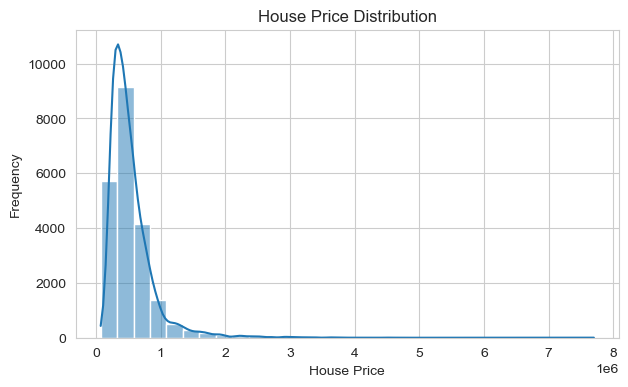

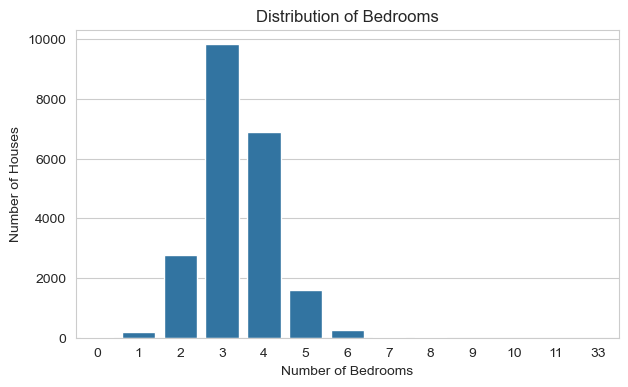

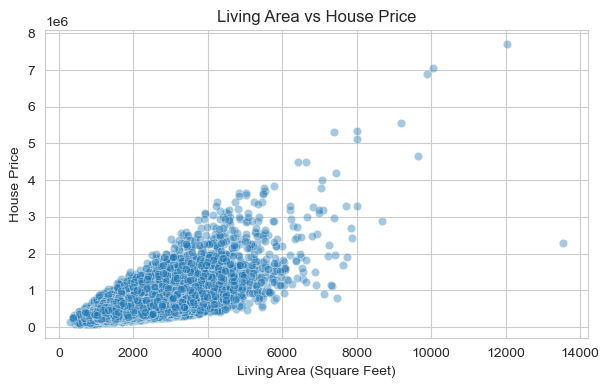

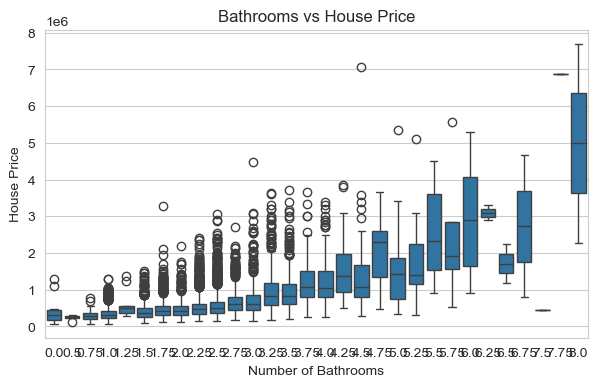

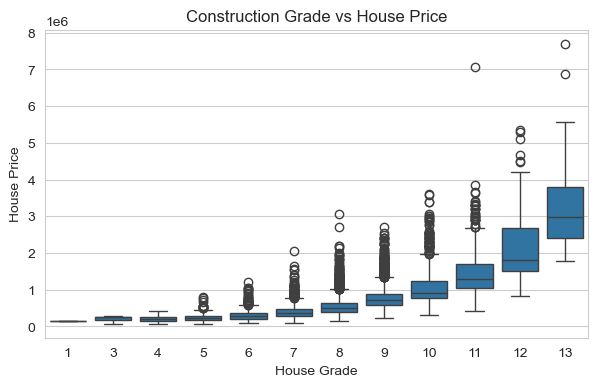

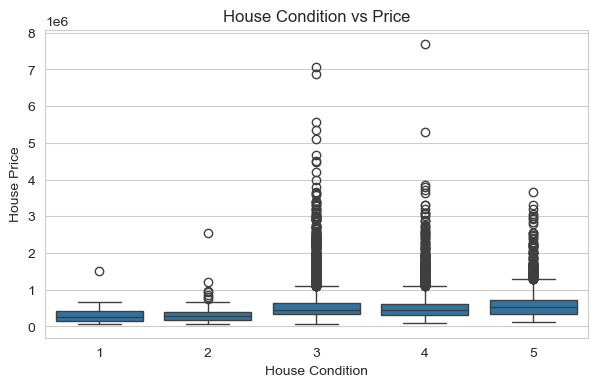

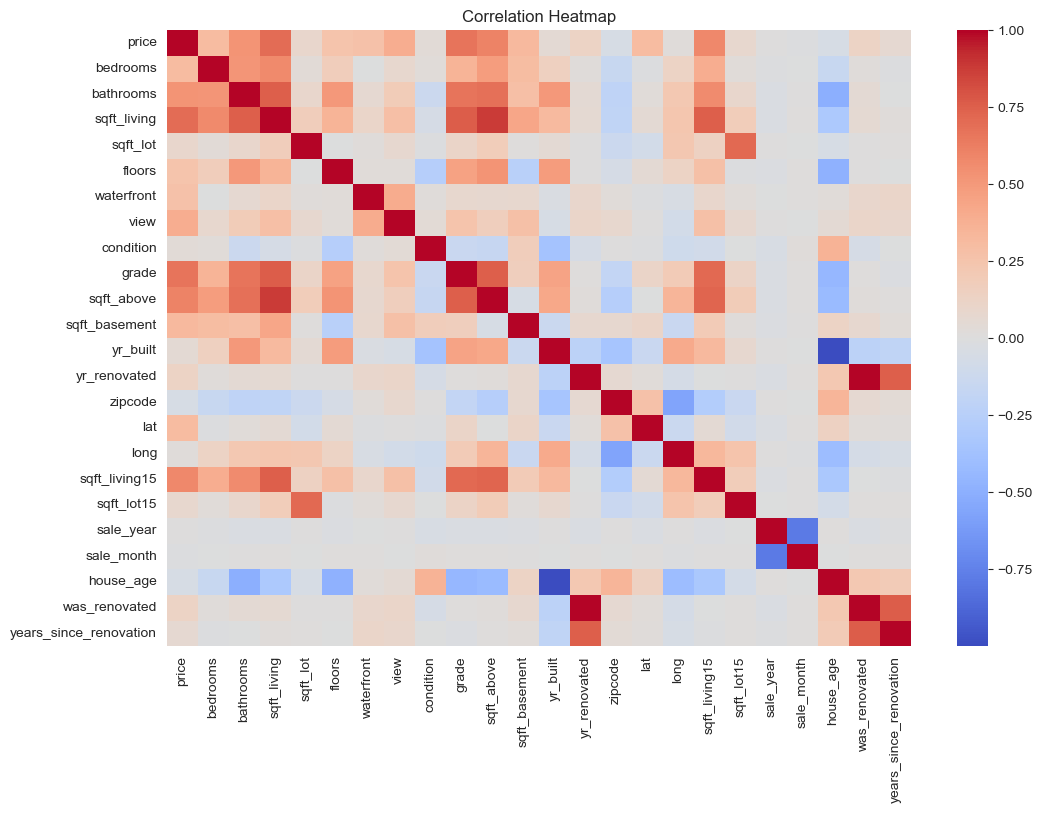

In [9]:
# 5. EXPLORATORY DATA ANALYSIS (EDA)

# A. House Price Distribution

plt.figure(figsize=(7, 4))

sns.histplot(
    data=df,
    x="price",
    bins=30,
    kde=True
)

plt.title("House Price Distribution")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()


# B. Number of Bedrooms

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="bedrooms"
)

plt.title("Distribution of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Number of Houses")

plt.show()


# C. Living Area vs House Price

plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=df,
    x="sqft_living",
    y="price",
    alpha=0.4
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("House Price")

plt.show()


# D. Bathrooms vs House Price

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="bathrooms",
    y="price"
)

plt.title("Bathrooms vs House Price")
plt.xlabel("Number of Bathrooms")
plt.ylabel("House Price")

plt.show()


# E. Grade vs House Price

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="grade",
    y="price"
)

plt.title("Construction Grade vs House Price")
plt.xlabel("House Grade")
plt.ylabel("House Price")

plt.show()


# F. House Condition vs Price

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="condition",
    y="price"
)

plt.title("House Condition vs Price")
plt.xlabel("House Condition")
plt.ylabel("House Price")

plt.show()


# G. Correlation Heatmap

plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=False,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [11]:
# 6. FEATURE SELECTION

# X contains input features
# y contains the target column

X = df.drop("price", axis=1)

y = df["price"]

print("\nInput Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nNumber of Input Features:", X.shape[1])


Input Features:
   bedrooms  bathrooms  sqft_living  sqft_lot  floors  waterfront  view  \
0         3       1.00         1180      5650     1.0           0     0   
1         3       2.25         2570      7242     2.0           0     0   
2         2       1.00          770     10000     1.0           0     0   
3         4       3.00         1960      5000     1.0           0     0   
4         3       2.00         1680      8080     1.0           0     0   

   condition  grade  sqft_above  ...  zipcode      lat     long  \
0          3      7        1180  ...    98178  47.5112 -122.257   
1          3      7        2170  ...    98125  47.7210 -122.319   
2          3      6         770  ...    98028  47.7379 -122.233   
3          5      7        1050  ...    98136  47.5208 -122.393   
4          3      8        1680  ...    98074  47.6168 -122.045   

   sqft_living15  sqft_lot15  sale_year  sale_month  house_age  was_renovated  \
0           1340        5650       2014         

In [13]:
# 7. SPLIT THE DATASET INTO TRAINING AND TESTING DATA

# 80% training data
# 20% testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)


Training Data Shape: (17290, 23)
Testing Data Shape: (4323, 23)


In [15]:
# 8. HANDLE MISSING VALUES

# Fill numerical missing values using median

numerical_columns = X_train.select_dtypes(
    include="number"
).columns

# Store median values for future predictions
numerical_medians = {}

for column in numerical_columns:

    median_value = X_train[column].median()

    numerical_medians[column] = median_value

    X_train[column] = X_train[column].fillna(median_value)

    X_test[column] = X_test[column].fillna(median_value)


print("\nMissing Values Handled Successfully!")

print("Training Missing Values:", X_train.isnull().sum().sum())

print("Testing Missing Values:", X_test.isnull().sum().sum())


Missing Values Handled Successfully!
Training Missing Values: 0
Testing Missing Values: 0


In [17]:
# 9. FEATURE ENCODING AND COLUMN ALIGNMENT

# The selected King County dataset contains numerical input features.
# Therefore, categorical encoding is not required.

# Make sure testing data has the same columns as training data

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Store feature names for the Streamlit application
feature_columns = X_train.columns.tolist()

print("\nFeature Preparation Completed!")

print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

print("\nInput Features:")
print(feature_columns)


Feature Preparation Completed!
Training Data Shape: (17290, 23)
Testing Data Shape: (4323, 23)

Input Features:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age', 'was_renovated', 'years_since_renovation']


In [19]:
# 10. TRAIN THE LINEAR REGRESSION MODEL

linear_model = LinearRegression()

# Train the model

linear_model.fit(
    X_train,
    y_train
)

print("\nLinear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [21]:
# 11. TRAIN THE RANDOM FOREST REGRESSION MODEL

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model

random_forest_model.fit(
    X_train,
    y_train
)

print("\nRandom Forest Regression Model Trained Successfully!")


Random Forest Regression Model Trained Successfully!


In [23]:
# 12. GENERATE PREDICTIONS

# Linear Regression predictions

linear_pred = linear_model.predict(X_test)

# Random Forest predictions

rf_pred = random_forest_model.predict(X_test)


print("\nActual Values:")
print(y_test.head(10).values)

print("\nLinear Regression Predicted Values:")
print(linear_pred[:10])

print("\nRandom Forest Predicted Values:")
print(rf_pred[:10])


Actual Values:
[ 365000.  865000. 1038000. 1490000.  711000.  211000.  790000.  680000.
  384500.  605000.]

Linear Regression Predicted Values:
[ 455445.41567613  744322.90507793 1228748.77332035 1683690.81871845
  723336.17108326  270955.86351939  824029.90710382  495851.03602983
  372987.32808715  466771.42617321]

Random Forest Predicted Values:
[ 378970.4   856766.11 1101931.7  1912839.5   709096.62  247932.59
  851893.45  626251.75  413248.67  527457.76]


In [25]:
# 13. LINEAR REGRESSION MODEL EVALUATION

linear_mae = mean_absolute_error(
    y_test,
    linear_pred
)

linear_mse = mean_squared_error(
    y_test,
    linear_pred
)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(
    y_test,
    linear_pred
)


print("\nLINEAR REGRESSION MODEL EVALUATION")
print("----------------------------------")

print("MAE:", round(linear_mae, 2))

print("MSE:", round(linear_mse, 2))

print("RMSE:", round(linear_rmse, 2))

print("R2 Score:", round(linear_r2, 4))

print("Train R2 Score:", round(linear_model.score(X_train, y_train), 4))

print("Test R2 Score:", round(linear_model.score(X_test, y_test), 4))


LINEAR REGRESSION MODEL EVALUATION
----------------------------------
MAE: 126638.33
MSE: 44728110238.67
RMSE: 211490.21
R2 Score: 0.7041
Train R2 Score: 0.7014
Test R2 Score: 0.7041


In [27]:
# 14. RANDOM FOREST MODEL EVALUATION

rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_mse = mean_squared_error(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(
    y_test,
    rf_pred
)


print("\nRANDOM FOREST MODEL EVALUATION")
print("------------------------------")

print("MAE:", round(rf_mae, 2))

print("MSE:", round(rf_mse, 2))

print("RMSE:", round(rf_rmse, 2))

print("R2 Score:", round(rf_r2, 4))

print("Train R2 Score:", round(random_forest_model.score(X_train, y_train), 4))

print("Test R2 Score:", round(random_forest_model.score(X_test, y_test), 4))


RANDOM FOREST MODEL EVALUATION
------------------------------
MAE: 72677.67
MSE: 22176397508.89
RMSE: 148917.42
R2 Score: 0.8533
Train R2 Score: 0.9834
Test R2 Score: 0.8533


In [29]:
# 15. MODEL COMPARISON

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "MSE": [linear_mse, rf_mse],
    "RMSE": [linear_rmse, rf_rmse],
    "R2 Score": [linear_r2, rf_r2]
})

print("\nMODEL COMPARISON RESULTS")

print(results)

# Select the model with the lower RMSE

if linear_rmse < rf_rmse:

    best_model = linear_model
    best_model_name = "Linear Regression"
    best_pred = linear_pred

else:

    best_model = random_forest_model
    best_model_name = "Random Forest"
    best_pred = rf_pred


print("\nBest Model Based on RMSE:", best_model_name)


MODEL COMPARISON RESULTS
               Model            MAE           MSE           RMSE  R2 Score
0  Linear Regression  126638.327871  4.472811e+10  211490.213104  0.704134
1      Random Forest   72677.668547  2.217640e+10  148917.418420  0.853308

Best Model Based on RMSE: Random Forest


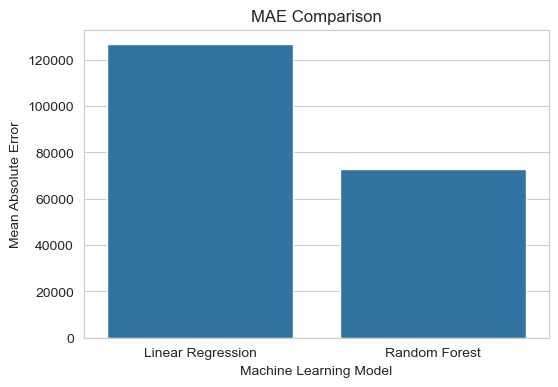

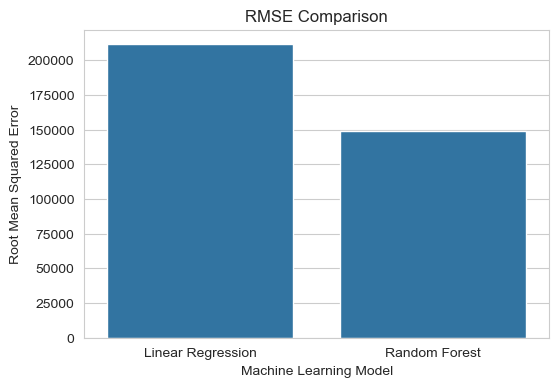

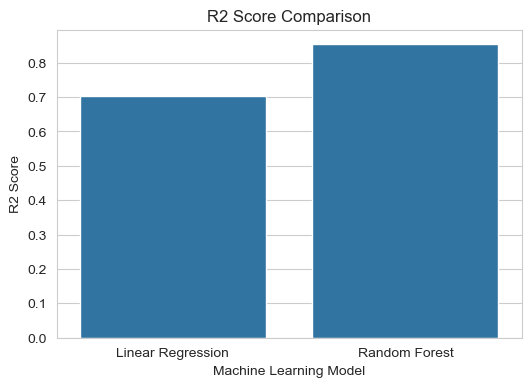

In [31]:
# 16. MODEL PERFORMANCE VISUALIZATION

# A. MAE Comparison

plt.figure(figsize=(6, 4))

sns.barplot(
    data=results,
    x="Model",
    y="MAE"
)

plt.title("MAE Comparison")

plt.xlabel("Machine Learning Model")

plt.ylabel("Mean Absolute Error")

plt.show()


# B. RMSE Comparison

plt.figure(figsize=(6, 4))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison")

plt.xlabel("Machine Learning Model")

plt.ylabel("Root Mean Squared Error")

plt.show()


# C. R2 Score Comparison

plt.figure(figsize=(6, 4))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("R2 Score Comparison")

plt.xlabel("Machine Learning Model")

plt.ylabel("R2 Score")

plt.show()

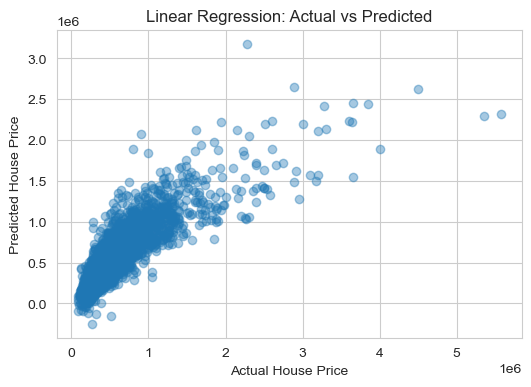

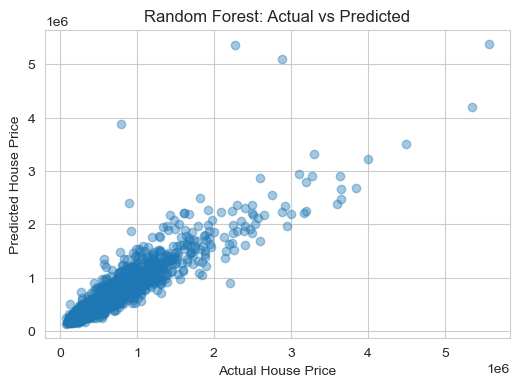

In [33]:
# 17. ACTUAL VS PREDICTED HOUSE PRICES

# Linear Regression

plt.figure(figsize=(6, 4))

plt.scatter(
    y_test,
    linear_pred,
    alpha=0.4
)

plt.xlabel("Actual House Price")

plt.ylabel("Predicted House Price")

plt.title("Linear Regression: Actual vs Predicted")

plt.show()


# Random Forest

plt.figure(figsize=(6, 4))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.4
)

plt.xlabel("Actual House Price")

plt.ylabel("Predicted House Price")

plt.title("Random Forest: Actual vs Predicted")

plt.show()


Feature Importance:
                   Feature  Importance
8                    grade    0.314104
2              sqft_living    0.273117
14                     lat    0.151410
15                    long    0.062361
5               waterfront    0.031779
16           sqft_living15    0.030119
20               house_age    0.023527
9               sqft_above    0.019720
13                 zipcode    0.014100
3                 sqft_lot    0.013067
11                yr_built    0.011831
17              sqft_lot15    0.011668
1                bathrooms    0.010507
6                     view    0.009982
10           sqft_basement    0.005411
19              sale_month    0.005304
0                 bedrooms    0.002906
7                condition    0.002720
4                   floors    0.001855
12            yr_renovated    0.001617
22  years_since_renovation    0.001411
18               sale_year    0.001205
21           was_renovated    0.000279


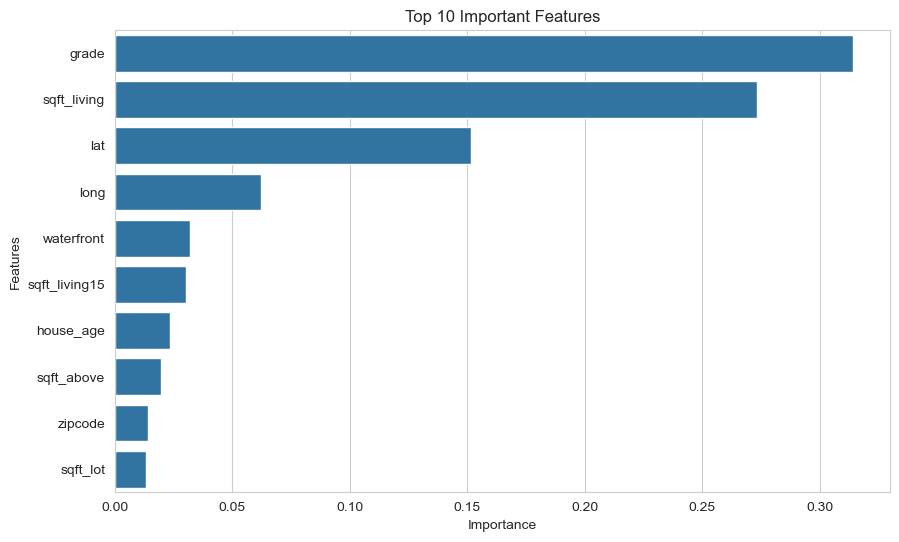

In [35]:
# 18. FEATURE IMPORTANCE USING RANDOM FOREST

feature_importance = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance": random_forest_model.feature_importances_

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")

print(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")

plt.xlabel("Importance")

plt.ylabel("Features")

plt.show()

In [37]:
# 19. SAMPLE HOUSE PRICE PREDICTION

# Select one house from the testing dataset
# This example uses real feature values from the dataset.

new_house = X_test.iloc[[0]].copy()

print("\nNew House Details:")
print(new_house)

# Predict house price using Linear Regression

linear_prediction = linear_model.predict(new_house)

# Predict house price using Random Forest

rf_prediction = random_forest_model.predict(new_house)


print("\nLINEAR REGRESSION PREDICTED PRICE:")
print("₹", round(linear_prediction[0], 2))

print("\nRANDOM FOREST PREDICTED PRICE:")
print("₹", round(rf_prediction[0], 2))

print("\nACTUAL HOUSE PRICE:")
print("₹", round(y_test.iloc[0], 2))


New House Details:
     bedrooms  bathrooms  sqft_living  sqft_lot  floors  waterfront  view  \
735         4       2.25         2070      8893     2.0           0     0   

     condition  grade  sqft_above  ...  zipcode      lat     long  \
735          4      8        2070  ...    98058  47.4388 -122.162   

     sqft_living15  sqft_lot15  sale_year  sale_month  house_age  \
735           2390        7700       2014          10         28   

     was_renovated  years_since_renovation  
735              0                       0  

[1 rows x 23 columns]

LINEAR REGRESSION PREDICTED PRICE:
₹ 455445.42

RANDOM FOREST PREDICTED PRICE:
₹ 378970.4

ACTUAL HOUSE PRICE:
₹ 365000.0


In [39]:
# 20. SAVE THE TRAINED MODELS FOR STREAMLIT

# Save Linear Regression model

joblib.dump(
    linear_model,
    "linear_regression_model.pkl"
)

# Save Random Forest model

joblib.dump(
    random_forest_model,
    "random_forest_model.pkl"
)

# Save preprocessing information

preprocessing_artifacts = {
    "feature_columns": feature_columns,
    "numerical_columns": list(numerical_columns),
    "numerical_medians": numerical_medians
}

joblib.dump(
    preprocessing_artifacts,
    "preprocessing_artifacts.pkl"
)


print("\nModels Saved Successfully!")

print("1. linear_regression_model.pkl")

print("2. random_forest_model.pkl")

print("3. preprocessing_artifacts.pkl")


Models Saved Successfully!
1. linear_regression_model.pkl
2. random_forest_model.pkl
3. preprocessing_artifacts.pkl


In [41]:
# 21. PROJECT SUMMARY

print("\n===================================")

print("HOUSE PRICE PREDICTION PROJECT")

print("===================================")

print("Algorithms: Linear Regression and Random Forest Regression")

print("Dataset Size:", df.shape)

print("Training Records:", X_train.shape[0])

print("Testing Records:", X_test.shape[0])

print("\nLinear Regression Results:")

print("MAE:", round(linear_mae, 2))

print("RMSE:", round(linear_rmse, 2))

print("R2 Score:", round(linear_r2, 4))


print("\nRandom Forest Results:")

print("MAE:", round(rf_mae, 2))

print("RMSE:", round(rf_rmse, 2))

print("R2 Score:", round(rf_r2, 4))


print("\nBest Model Based on RMSE:", best_model_name)

print("\nProject Completed Successfully!")


HOUSE PRICE PREDICTION PROJECT
Algorithms: Linear Regression and Random Forest Regression
Dataset Size: (21613, 24)
Training Records: 17290
Testing Records: 4323

Linear Regression Results:
MAE: 126638.33
RMSE: 211490.21
R2 Score: 0.7041

Random Forest Results:
MAE: 72677.67
RMSE: 148917.42
R2 Score: 0.8533

Best Model Based on RMSE: Random Forest

Project Completed Successfully!
